# 08｜先把证据与计算做好，再考虑 RAG 和 Agent

本书把 ML4Trading 第 22 章中“检索、计算、引用、拒答”的分工缩成一个可复查的小例子。它没有调用大模型，不下载 embedding 模型，也不冒充已经搭好完整 RAG。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 一个好问题要足够具体

“AI 投资好吗”无法从 12 行数据回答。“Amazon 2024 年披露 FCF 如何与现金流量表桥接”可以。检索先按实体、期间和指标过滤，金额由代码计算，再返回来源和限制。

In [2]:
facts=load_frame("ai_annual")
def evidence_answer(symbol,year):
    selected=facts[(facts.symbol==symbol)&(facts.fiscal_year==year)]
    if len(selected)!=1:
        return {"status":"证据不足","reason":"本年度种子表没有唯一匹配记录；不猜值"}
    row=selected.iloc[0]
    return {"status":"有限回答","symbol":symbol,"period_end":row.period_end,"unit":"百万美元","cfo":row.cfo_usd_m,"cash_ppe":row.cash_ppe_usd_m,"cash_surplus":row.cfo_usd_m-row.cash_ppe_usd_m,"source":row.source_url,"limitation":"统一现金剩余，不代表公司FCF或AI项目收益"}
display(evidence_answer("AMZN",2024))
display(evidence_answer("NVDA",2024))

{'status': '有限回答',
 'symbol': 'AMZN',
 'period_end': '2024-12-31',
 'unit': '百万美元',
 'cfo': np.int64(115877),
 'cash_ppe': np.int64(82999),
 'cash_surplus': np.int64(32878),
 'source': 'https://www.sec.gov/Archives/edgar/data/1018724/000101872425000004/amzn-20241231.htm',
 'limitation': '统一现金剩余，不代表公司FCF或AI项目收益'}

{'status': '证据不足', 'reason': '本年度种子表没有唯一匹配记录；不猜值'}

## 2. 三种状态不能混淆

“没有证据”不是“数值为零”；“检索命中”不是“指标可比”；“引用链接存在”不是“引用内容支持这句话”。本例为缺资料的 NVDA 拒答，不用别家公司的数值代替。

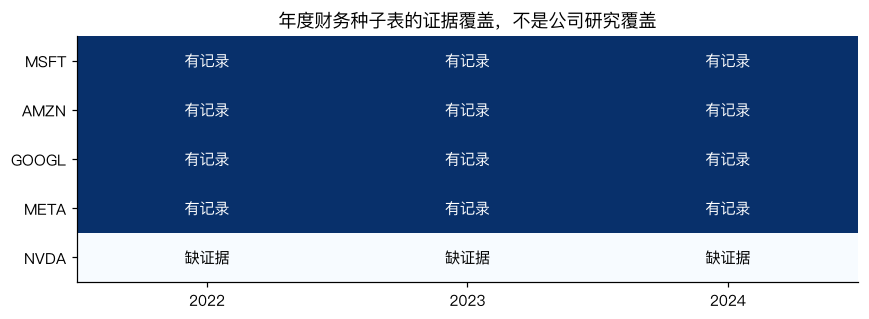

In [3]:
coverage=facts.pivot_table(index="symbol",columns="fiscal_year",values="revenue_usd_m",aggfunc="count").reindex(["MSFT","AMZN","GOOGL","META","NVDA"]).fillna(0)
fig,ax=plt.subplots(figsize=(8,3)); im=ax.imshow(coverage,aspect="auto",vmin=0,vmax=1,cmap="Blues")
ax.set_xticks(range(len(coverage.columns)),coverage.columns); ax.set_yticks(range(len(coverage.index)),coverage.index)
for i in range(len(coverage)):
    for j in range(len(coverage.columns)):ax.text(j,i,"有记录" if coverage.iloc[i,j] else "缺证据",ha="center",va="center",color="white" if coverage.iloc[i,j] else "black")
ax.grid(False); ax.set_title("年度财务种子表的证据覆盖，不是公司研究覆盖")
plt.tight_layout(); plt.show()

## 3. 真正接入财报文本后怎么扩展

文档保留公司永久标识、报告类型、财政期、公告时刻、取得时刻、原文件摘要和页码。先按实体、时点和章节过滤，再检索候选段落。表格保持行列与单位，不按固定字符长度切断。答案拆成事实、计算、推断；每条事实回链到支持它的原段。

验证至少包含：检索是否找对文档、表格是否解析正确、计算是否正确、引用是否支持结论、缺材料时是否拒答。模型分数不能替代这些检查。

## 4. 与本项目现有结构对接

Java 负责正式来源与写入；本课程只用 Java 下载有限研究原件，Python 负责本地分析。Notebook 解释过程，公共函数只保留容量、读数、口径和少量分析。已有 `plan_1029_research.py` 继续唯一承担相同基线的执行。

扩展时优先补来源契约与验证，不把公司会计规则放进通用 utils，也不把 RAG 回答直接写回正式财务表。

参考：[ML4T 第22章](https://github.com/stefan-jansen/machine-learning-for-trading/tree/main/22_rag_financial_research)。